Proyecto de Aprendizaje Automático: Predicción de Consumo de Agua Potable en la ciudad de Ushuaia.
## Entrega 2: Análisis Exploratorio, Carga y Preprocesamiento de Datos


In [ ]:
# Importación de librerías esenciales para análisis de datos y visualización
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilos para gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

## 1-Carga data set


In [ ]:
# Carga del dataset meteorológico
df_smn = pd.read_csv("smn_ushuaia_temperatura_precipitacion_2025_2026.csv")

# Carga del dataset de consumo de red
df_consump = pd.read_csv("temetra-network-consumption .csv")

print("--- Dataset SMN (Meteorología) ---")
display(df_smn.head())
print("\nDimensiones:", df_smn.shape)

print("\n--- Dataset Consumo de Red (Temetra) ---")
display(df_consump.head(3))
print("\nDimensiones:", df_consump.shape)

--- Dataset SMN (Meteorología) ---


,fecha,temp_media_c,temp_min_c,temp_max_c,precipitacion_mm,evento_congelamiento
0,2025-01-01,12.0,6.5,15.5,0.0,0
1,2025-01-02,10.6,8.0,14.1,0.9,0
2,2025-01-03,12.3,6.9,17.0,0.8,0
3,2025-01-04,14.3,10.6,18.2,0.0,0
4,2025-01-05,10.4,5.3,13.6,3.4,0



Dimensiones: (638, 6)

--- Dataset Consumo de Red (Temetra) ---


,ACCOUNTREF,NAME,CREF,METERSERIAL,MREF,INSTALL DATE,EXCLUDEFROMHANDHELD,IS BILLING?,REASONFORNONBILLING,REPLACED?,REPLACED BY,ROUTE,DMA,ENGINEERINGZONE,CATEGORY,BILLGROUP,ALLOWANCESCOUNT,SEWERAGE,GPS,IG-EASTING,IG-NORTHING,FROMREADDATE,FROMREADINDEX,FROMREADTYPE,TOREADDATE,TOREADINDEX,TOREADTYPE,CONSUMPTION,FLOWRATE-M3
0,1443 - (SISA),CENHEUS - Sanchez Posleman,NaN,I17VA001735,NaN,31/10/2018,no,no,NaN,no,NaN,PIPO-DON BOSCO,default DMA,NaN,NaN,1,NaN,no,S54.81579 W68.32305,-3.317301e+06,-1.354662e+07,2025-01-01 00:00:00,15750.0,FDR,2026-09-07 00:00:00,21406.0,Estimate,"5656,0","9,2099"
1,14343 - (SISA),Defensa Civil,NaN,I17VA004825,NaN,19/06/2019,no,no,NaN,no,NaN,PIPO-DON BOSCO,default DMA,NaN,NaN,1,NaN,no,"@-54.8237064,-68.3300653",-3.316745e+06,-1.354762e+07,2025-01-01 00:00:00,3097.0,FDR,2026-09-07 00:00:00,3935.0,Estimate,"838,0","1,3645"
2,5669,COLIN ASENCIO Erika Miriam,NaN,I17VA001734,NaN,01/12/2018,no,no,NaN,no,NaN,PIPO-DON BOSCO,default DMA,NaN,NaN,1,NaN,no,S54.81575 W68.33765,-3.317924e+06,-1.354752e+07,2025-01-01 00:00:00,6015.0,FDR,2026-09-07 00:00:00,6977.0,Estimate,"962,0","1,5665"



Dimensiones: (423, 29)


## 2. Análisis Exploratorio Inicial (EDA) y Tipos de Datos
Verificamos los tipos de datos, la presencia de valores nulos y las estadísticas descriptivas básicas de ambas fuentes.

In [ ]:
print("=== INFORMACIÓN SMN ===")
df_smn.info()
print("\nEstadísticas descriptivas SMN:")
display(df_smn.describe())

print("\n=== INFORMACIÓN CONSUMO RED ===")
df_consump.info()
print("\nValores nulos en Consumo Red:")
missing_values = df_consump.isnull().sum()
display(missing_values[missing_values > 0])



=== INFORMACIÓN SMN ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 638 entries, 0 to 637
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fecha                 638 non-null    object 
 1   temp_media_c          638 non-null    float64
 2   temp_min_c            638 non-null    float64
 3   temp_max_c            638 non-null    float64
 4   precipitacion_mm      638 non-null    float64
 5   evento_congelamiento  638 non-null    int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 30.0+ KB

Estadísticas descriptivas SMN:


,temp_media_c,temp_min_c,temp_max_c,precipitacion_mm,evento_congelamiento
count,638.00000,638.000000,638.000000,638.000000,638.000000
mean,6.20047,2.202665,10.196865,1.362226,0.329154
std,3.86768,3.910876,3.969094,2.650707,0.470275
min,-3.20000,-6.900000,0.300000,0.000000,0.000000
25%,3.00000,-0.800000,7.200000,0.000000,0.000000
50%,6.10000,2.200000,10.000000,0.000000,0.000000
75%,9.20000,5.200000,13.300000,1.500000,1.000000
max,15.80000,12.000000,20.500000,20.600000,1.000000



=== INFORMACIÓN CONSUMO RED ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 423 entries, 0 to 422
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ACCOUNTREF           423 non-null    object 
 1   NAME                 423 non-null    object 
 2   CREF                 191 non-null    object 
 3   METERSERIAL          423 non-null    object 
 4   MREF                 2 non-null      object 
 5   INSTALL DATE         238 non-null    object 
 6   EXCLUDEFROMHANDHELD  423 non-null    object 
 7   IS BILLING?          423 non-null    object 
 8   REASONFORNONBILLING  1 non-null      object 
 9   REPLACED?            423 non-null    object 
 10  REPLACED BY          0 non-null      float64
 11  ROUTE                423 non-null    object 
 12  DMA                  423 non-null    object 
 13  ENGINEERINGZONE      0 non-null      float64
 14  CATEGORY             0 non-null      float64
 15  BILLGRO

,0
CREF,232
MREF,421
INSTALL DATE,185
REASONFORNONBILLING,422
REPLACED BY,423
ENGINEERINGZONE,423
CATEGORY,423
ALLOWANCESCOUNT,423
FROMREADDATE,1
FROMREADINDEX,1


## 3. Limpieza y Transformación de Datos
En los datos de consumo (`df_consump`), columnas clave como `CONSUMPTION` y `FLOWRATE-M3` se encuentran en formato de texto debido al uso de comas (`,`) como separador decimal. Procedemos a limpiarlos y convertirlos a valores numéricos (`float`). Asimismo, estandarizamos las fechas a formato `datetime`.

In [ ]:
# Limpieza de columnas numéricas que utilizan coma decimal en el dataset de consumo
if df_consump['CONSUMPTION'].dtype == 'object':
    df_consump['CONSUMPTION'] = df_consump['CONSUMPTION'].str.replace(',', '.').astype(float)

if df_consump['FLOWRATE-M3'].dtype == 'object':
    df_consump['FLOWRATE-M3'] = df_consump['FLOWRATE-M3'].str.replace(',', '.').astype(float)

# Conversión de fechas a tipo datetime
df_smn['fecha'] = pd.to_datetime(df_smn['fecha'])
df_consump['FROMREADDATE'] = pd.to_datetime(df_consump['FROMREADDATE'], errors='coerce')
df_consump['TOREADDATE'] = pd.to_datetime(df_consump['TOREADDATE'], errors='coerce')


display(df_consump[['CONSUMPTION', 'FLOWRATE-M3']].describe())

#  Corrección de comas decimales a float en variables de consumo/caudal
for col in ['CONSUMPTION', 'FLOWRATE-M3']:
    if col in df_consump.columns and df_consump[col].dtype == 'object':
        df_consump[col] = df_consump[col].str.replace(',', '.').astype(float)




,CONSUMPTION,FLOWRATE-M3
count,414.000000,414.000000
mean,3797.291727,6.216478
std,5381.269963,8.743872
min,0.000000,0.000000
25%,648.270750,1.059475
50%,1790.500000,2.961150
75%,4462.601750,7.317925
max,37521.130000,61.556700


## 4. Visualización Exploratoria de Variables Exógenas (SMN)
Analizamos el comportamiento de la temperatura y las precipitaciones en Ushuaia durante el período de estudio para entender la estacionalidad climática.

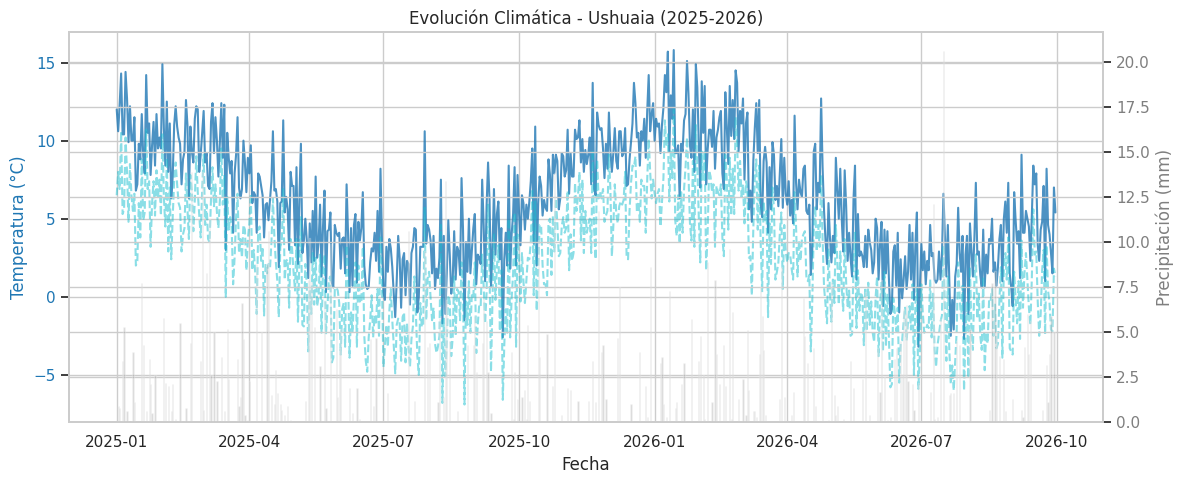

In [ ]:
fig, ax1 = plt.subplots(figsize=(12, 5))

# Gráfica de temperaturas
ax1.plot(df_smn['fecha'], df_smn['temp_media_c'], color='tab:blue', label='Temp Media (°C)', alpha=0.8)
ax1.plot(df_smn['fecha'], df_smn['temp_min_c'], color='tab:cyan', linestyle='--', label='Temp Mín (°C)', alpha=0.5)
ax1.set_ylabel('Temperatura (°C)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.set_xlabel('Fecha')

# Gráfica de precipitaciones en eje secundario
ax2 = ax1.twinx()
ax2.bar(df_smn['fecha'], df_smn['precipitacion_mm'], color='tab:gray', alpha=0.3, label='Precipitación (mm)')
ax2.set_ylabel('Precipitación (mm)', color='tab:gray')
ax2.tick_params(axis='y', labelcolor='tab:gray')

plt.title('Evolución Climática - Ushuaia (2025-2026)')
fig.tight_layout()
plt.show()

## 5-Integracion de ambos data set

In [ ]:
# Extracción de variables de tiempo sobre el dataset meteorológico (base diaria)
df_smn['anio'] = df_smn['fecha'].dt.year
df_smn['mes'] = df_smn['fecha'].dt.month
df_smn['dia_semana'] = df_smn['fecha'].dt.dayofweek
df_smn['es_fin_de_semana'] = df_smn['dia_semana'].apply(lambda x: 1 if x >= 5 else 0)

# Creación de variables de rezago (Lag Features) de ejemplo para la temperatura media (t-1, t-7)
df_smn['temp_media_lag_1'] = df_smn['temp_media_c'].shift(1)
df_smn['temp_media_lag_7'] = df_smn['temp_media_c'].shift(7)

# Promedio móvil de 7 días para suavizar fluctuaciones climáticas
df_smn['temp_media_ma_7'] = df_smn['temp_media_c'].rolling(window=7).mean()

# Visualización de las nuevas características generadas
display(df_smn[['fecha', 'temp_media_c', 'temp_media_lag_1', 'temp_media_ma_7', 'evento_congelamiento']].head(10))

,fecha,temp_media_c,temp_media_lag_1,temp_media_ma_7,evento_congelamiento
0,2025-01-01,12.0,NaN,NaN,0
1,2025-01-02,10.6,12.0,NaN,0
2,2025-01-03,12.3,10.6,NaN,0
3,2025-01-04,14.3,12.3,NaN,0
4,2025-01-05,10.4,14.3,NaN,0
5,2025-01-06,10.4,10.4,NaN,0
6,2025-01-07,14.4,10.4,12.057143,0
7,2025-01-08,12.7,14.4,12.157143,0
8,2025-01-09,9.9,12.7,12.057143,0
9,2025-01-10,12.2,9.9,12.042857,0


## 6- Tratamiento de valores nulos y valores atipicos

Valores nulos por columna:
ACCOUNTREF                      0
NAME                            0
CREF                          226
METERSERIAL                     0
MREF                          412
INSTALL DATE                  182
EXCLUDEFROMHANDHELD             0
IS BILLING?                     0
REASONFORNONBILLING           413
REPLACED?                       0
REPLACED BY                   414
ROUTE                           0
DMA                             0
ENGINEERINGZONE               414
CATEGORY                      414
BILLGROUP                       0
ALLOWANCESCOUNT               414
SEWERAGE                        0
GPS                             0
IG-EASTING                      0
IG-NORTHING                     0
FROMREADDATE                    0
FROMREADINDEX                   0
FROMREADTYPE                    0
TOREADDATE                      0
TOREADINDEX                     0
TOREADTYPE                      0
CONSUMPTION                     0
FLOWRATE-M3          

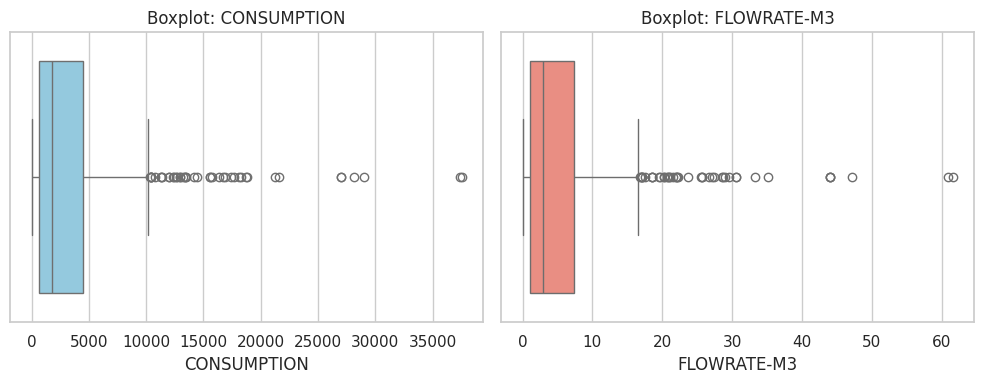

In [ ]:
# 1. Conteo de valores nulos por columna en el dataset fusionado
print("Valores nulos por columna:")
print(df_consump.isnull().sum())

# 2. Estrategia de Imputación para variables numéricas (Consumo y Clima)
# Para variables continuas de consumo o caudal, la MEDIANA es robusta frente a sesgos o valores extremos.
df_consump["CONSUMPTION"] = df_consump["CONSUMPTION"].fillna(
    df_consump["CONSUMPTION"].median()
)
df_consump["FLOWRATE-M3"] = df_consump["FLOWRATE-M3"].fillna(
    df_consump["FLOWRATE-M3"].median()
)

# Para las variables climáticas agregadas que se cruzaron del SMN:
df_consump["clima_temp_media_periodo"] = df_consump[
    "clima_temp_media_periodo"
].fillna(df_consump["clima_temp_media_periodo"].mean())
df_consump["clima_precip_total_periodo"] = df_consump[
    "clima_precip_total_periodo"
].fillna(0)  # Si no hubo registro, se asume 0 precipitación
df_consump["clima_dias_congelamiento"] = df_consump[
    "clima_dias_congelamiento"
].fillna(0)

print(df_consump.isnull().sum())

import matplotlib.pyplot as plt
import seaborn as sns

# Configuración del gráfico
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.boxplot(x=df_consump['CONSUMPTION'], color='skyblue')
plt.title('Boxplot: CONSUMPTION')

plt.subplot(1, 2, 2)
sns.boxplot(x=df_consump['FLOWRATE-M3'], color='salmon')
plt.title('Boxplot: FLOWRATE-M3')

plt.tight_layout()
plt.show()

## 7. Ingeniería de Características Preliminar (Feature Engineering)
Para preparar los datos de cara al modelado supervisado de regresión, estructuramos características temporales clave a partir de la fecha (mes, día de la semana, estación) y dejamos listas las bases para la creación de rezagros (`lags`) y ventanas deslizantes.

In [ ]:
# Función para calcular el clima promedio durante el período de lectura de cada medidor
def obtener_clima_periodo(row):
    inicio = row['FROMREADDATE']
    fin = row['TOREADDATE']

    if pd.isna(inicio) or pd.isna(fin):
        return pd.Series([np.nan, np.nan, np.nan])

    # Mascara y filtrado alineados correctamente
    mask = (df_smn['fecha'] >= inicio) & (df_smn['fecha'] <= fin)
    df_periodo = df_smn.loc[mask]

    if len(df_periodo) == 0:
        return pd.Series([np.nan, np.nan, np.nan])

    # Calculamos métricas climáticas agregadas para ese rango
    temp_media_prom = df_periodo['temp_media_c'].mean()
    precip_total = df_periodo['precipitacion_mm'].sum()
    congelamiento_dias = df_periodo['evento_congelamiento'].sum()

    return pd.Series([temp_media_prom, precip_total, congelamiento_dias])

print("Calculando variables meteorológicas integradas por medidor...")

# Aplicamos la función a cada fila del dataset de consumo
df_consump[['clima_temp_media_periodo', 'clima_precip_total_periodo', 'clima_dias_congelamiento']] = df_consump.apply(obtener_clima_periodo, axis=1)

# Verificamos el dataset fusionado resultante

display(df_consump[['ACCOUNTREF', 'CONSUMPTION', 'FLOWRATE-M3', 'clima_temp_media_periodo', 'clima_precip_total_periodo', 'clima_dias_congelamiento']].head())

Calculando variables meteorológicas integradas por medidor...


,ACCOUNTREF,CONSUMPTION,FLOWRATE-M3,clima_temp_media_periodo,clima_precip_total_periodo,clima_dias_congelamiento
0,1443 - (SISA),5656.0,9.2099,6.252683,829.5,200.0
1,14343 - (SISA),838.0,1.3645,6.252683,829.5,200.0
2,5669,962.0,1.5665,6.252683,829.5,200.0
3,7962 - (SISA),759.0,1.2359,6.252683,829.5,200.0
4,994 - (SISA),1651.0,2.6884,6.252683,829.5,200.0


## Diccionario de Datos: Dataset Fusionado (Consumo de Agua y Clima - Ushuaia)

A continuación se detalla la estructura final del dataset integrado, que combina los registros operativos de la red de medidores (Temetra / DPOSS) con las variables meteorológicas exógenas provistas por el Servicio Meteorológico Nacional (SMN) para la ciudad de Ushuaia.

| Columna / Variable | Tipo de Dato | Origen / Fuente | Descripción Detallada |
| :--- | :--- | :--- | :--- |
| **`ACCOUNTREF`** | `object` / `str` | Temetra (DPOSS) | Identificador o número de cuenta único asociado al punto de suministro (medidor domiciliario o comercial). |
| **`NAME`** | `object` / `str` | Temetra (DPOSS) | Titular o referencia alfanumérica del suministro relevado en la red. |
| **`METERSERIAL`** | `object` / `str` | Temetra (DPOSS) | Número de serie físico del medidor instalado en el nodo. |
| **`ROUTE`** | `object` / `str` | Temetra (DPOSS) | Ruta de lectura asignada para los operarios de campo en el distrito de medición. |
| **`DMA`** | `object` / `str` | Temetra (DPOSS) | Distrito de Medición Acotado (*District Metered Area*), indicador del sector o zona hidráulica de la red. |
| **`FROMREADDATE`** | `datetime64` | Temetra (DPOSS) | Fecha de inicio del período de lectura del medidor. |
| **`TOREADDATE`** | `datetime64` | Temetra (DPOSS) | Fecha de cierre o fin del período de lectura del medidor. |
| **`CONSUMPTION`** | `float64` | Temetra (DPOSS) | Volumen total de agua potable consumido y registrado por el medidor durante el período del intervalo ($m^3$). |
| **`FLOWRATE-M3`** | `float64` | Temetra (DPOSS) | Caudal promedio estimado o calculado para el punto de suministro ($m^3$ por unidad de tiempo de lectura). |
| **`clima_temp_media_periodo`** | `float64` | SMN (Ushuaia) | Temperatura media ambiente promedio registrada por la estación del SMN durante el rango de fechas entre `FROMREADDATE` y `TOREADDATE` (°C). |
| **`clima_precip_total_periodo`** | `float64` | SMN (Ushuaia) | Acumulado total de precipitaciones (lluvia, nieve u otros hidrometeoros) registrado por el SMN en el intervalo de lectura del medidor (mm). |
| **`clima_dias_congelamiento`** | `int64` | SMN (Ushuaia) | Cantidad de días dentro del período de lectura que registraron temperaturas o condiciones críticas de helada / congelamiento en la red. |

### Notas Metodológicas:
* **Variable Objetivo ($y$):** Se define principalmente sobre `CONSUMPTION` (volumen absoluto) o `FLOWRATE-M3` (caudal promedio) para las tareas de regresión supervisada.
* **Variables Exógenas ($X$):** Las columnas con prefijo `clima_` actúan como predictores ambientales exógenos que alimentan el pipeline de Machine Learning junto con las características temporales y de rezagado (*lags*).

8- Visualizacion integral

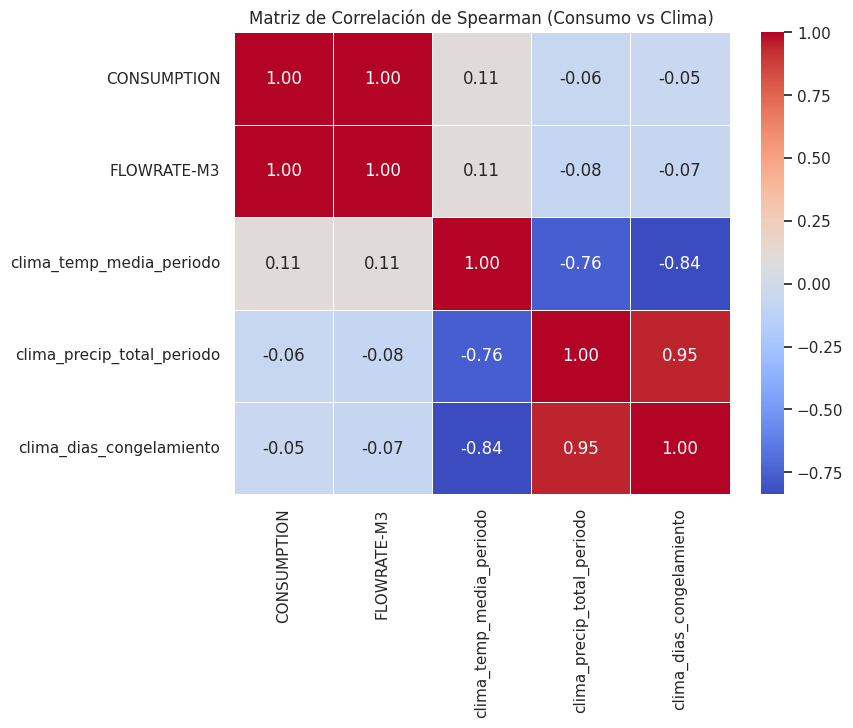

In [ ]:
# Mapa de calor de correlaciones (Spearman) para detectar relaciones numéricas
cols_corr = ['CONSUMPTION', 'FLOWRATE-M3', 'clima_temp_media_periodo', 'clima_precip_total_periodo', 'clima_dias_congelamiento']
corr = df_consump[cols_corr].corr(method='spearman')

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Matriz de Correlación de Spearman (Consumo vs Clima)")
plt.show()

## 9- Pipeline y preprocesamiento del modelado

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Definición de la Variable Objetivo (y) y Características (X)
target = 'CONSUMPTION'

# Seleccionamos variables predictoras numéricas y categóricas clave
features_num = ['clima_temp_media_periodo', 'clima_precip_total_periodo', 'clima_dias_congelamiento']
features_cat = ['ROUTE', 'DMA']

# Limpiamos filas donde el target sea nulo para evitar errores
df_model = df_consump.dropna(subset=[target] + features_num).copy()

X = df_model[features_num + features_cat]
y = df_model[target]

print(f"Dimensiones de la matriz de características X: {X.shape}")
print(f"Dimensiones de la variable objetivo y: {y.shape}")

# 2. Partición de Datos (Train / Test) - 80% entrenamiento, 20% prueba
# Nota: Para series temporales estrictas, se recomienda orden cronológico por fecha de inicio.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Instancias de Entrenamiento (Train): {X_train.shape[0]}")
print(f"Instancias de Prueba (Test): {X_test.shape[0]}")

# 3. Construcción del Pipeline de Preprocesamiento
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), features_num),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Desconocido')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), features_cat)
    ]
)



Dimensiones de la matriz de características X: (422, 5)
Dimensiones de la variable objetivo y: (422,)
Instancias de Entrenamiento (Train): 337
Instancias de Prueba (Test): 85


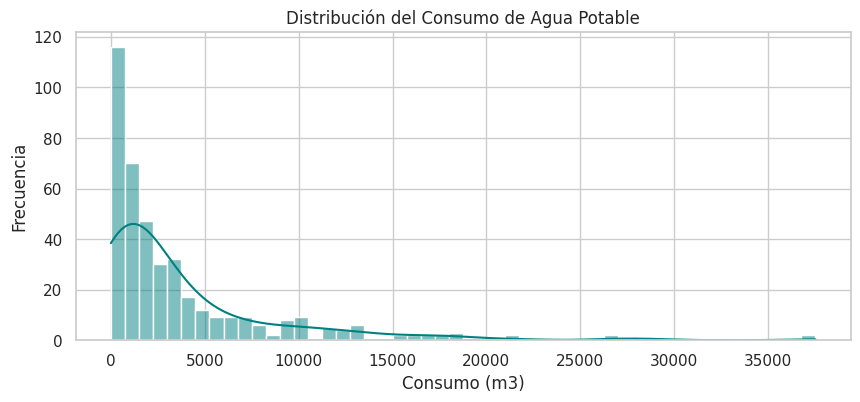

In [ ]:
plt.figure(figsize=(10, 4))
sns.histplot(df_consump['CONSUMPTION'].dropna(), bins=50, kde=True, color='teal')
plt.title('Distribución del Consumo de Agua Potable')
plt.xlabel('Consumo (m3)')
plt.ylabel('Frecuencia')
plt.show()

-Transformación y Agregación de la Demanda Diaria a Nivel de Red

In [92]:
import pandas as pd
import numpy as np

# 1. Asegurar tipos de datos datetime y numéricos
df_consump['FROMREADDATE'] = pd.to_datetime(df_consump['FROMREADDATE'])
df_consump['TOREADDATE'] = pd.to_datetime(df_consump['TOREADDATE'])
df_consump['CONSUMPTION'] = (
    df_consump['CONSUMPTION']
    .astype(str)
    .str.replace(',', '.')
    .astype(float)
)

# 2. Filtrar filas con fechas nulas o periodos inválidos
df_clean = df_consump.dropna(subset=['FROMREADDATE', 'TOREADDATE', 'CONSUMPTION']).copy()
df_clean = df_clean[df_clean['TOREADDATE'] > df_clean['FROMREADDATE']]

# 3. Función para desplegar el consumo diario por periodo de cada medidor
records = []
for idx, row in df_clean.iterrows():
    # Rango de días del periodo de lectura
    dates = pd.date_range(start=row['FROMREADDATE'].date(), end=row['TOREADDATE'].date(), freq='D')
    dias_periodo = len(dates)

    if dias_periodo > 0:
        consumo_diario = row['CONSUMPTION'] / dias_periodo
        for d in dates:
            records.append({
                'fecha': d,
                'ACCOUNTREF': row['ACCOUNTREF'],
                'ROUTE': row['ROUTE'],
                'consumo_diario_m3': consumo_diario
            })

# 4. Crear DataFrame desplegado a nivel diario
df_diario_desplegado = pd.DataFrame(records)

# 5. Agrupar la demanda total diaria de agua potable en Ushuaia (m3)
df_consumo_diario_total = (
    df_diario_desplegado
    .groupby('fecha')['consumo_diario_m3']
    .sum()
    .reset_index()
    .rename(columns={'consumo_diario_m3': 'consumo_total_m3'})
)

print("Consumo diario prorrateado")
print(df_consumo_diario_total.head())

Consumo diario prorrateado
       fecha  consumo_total_m3
0 2024-12-02         77.107047
1 2024-12-03        127.911305
2 2024-12-04        127.911305
3 2024-12-05        127.911305
4 2024-12-06        127.911305


Ingeniería de Características (Feature Engineering) y Consolidación del Dataset Final para Modelado

In [93]:
# 1. Formato datetime en SMN y fusión de datasets
df_smn['fecha'] = pd.to_datetime(df_smn['fecha'])
df_ml = pd.merge(df_smn, df_consumo_diario_total, on='fecha', how='inner')

# Ordenar cronológicamente (vital para series temporales)
df_ml = df_ml.sort_values('fecha').reset_index(drop=True)

# 2. Variables Temporales y Cíclicas
df_ml['mes'] = df_ml['fecha'].dt.month
df_ml['dia_semana'] = df_ml['fecha'].dt.dayofweek
df_ml['es_fin_de_semana'] = df_ml['dia_semana'].isin([5, 6]).astype(int)

# Codificación Cíclica (Seno / Coseno para estacionalidad)
df_ml['sin_mes'] = np.sin(2 * np.pi * df_ml['mes'] / 12)
df_ml['cos_mes'] = np.cos(2 * np.pi * df_ml['mes'] / 12)
df_ml['sin_dia_semana'] = np.sin(2 * np.pi * df_ml['dia_semana'] / 7)
df_ml['cos_dia_semana'] = np.cos(2 * np.pi * df_ml['dia_semana'] / 7)

# 3. Variables de Rezago (Lags de Temperatura y Precipitación)
for lag in [1, 2, 3, 7]:
    df_ml[f'temp_media_lag_{lag}'] = df_ml['temp_media_c'].shift(lag)
    df_ml[f'temp_min_lag_{lag}'] = df_ml['temp_min_c'].shift(lag)
    df_ml[f'precip_lag_{lag}'] = df_ml['precipitacion_mm'].shift(lag)

# 4. Ventanas Móviles (Rolling Windows)
# Promedio de temperatura de los últimos 3 y 7 días (efecto acumulativo de heladas)
df_ml['temp_media_roll_3d'] = df_ml['temp_media_c'].rolling(window=3).mean()
df_ml['temp_media_roll_7d'] = df_ml['temp_media_c'].rolling(window=7).mean()
df_ml['precip_roll_3d'] = df_ml['precipitacion_mm'].rolling(window=3).sum()

# Eliminar filas iniciales generadas por los lags/rolling nulos
df_ml = df_ml.dropna().reset_index(drop=True)

print("Dataset preparado con Feature Engineering:")
print(f"Dimensiones del dataset listo para ML: {df_ml.shape}")

Dataset preparado con Feature Engineering:
Dimensiones del dataset listo para ML: (608, 29)


Preparación de Datos y División Cronológica para Entrenamiento y Evaluación

In [94]:
from sklearn.preprocessing import RobustScaler

# 1. Transformación logarítmica de la Variable Objetivo (mitigar asimetría de consumo)
df_ml['target_log_consumo'] = np.log1p(df_ml['consumo_total_m3'])

# 2. Definición de Features (X) y Target (y)
features_cols = [
    'temp_media_c', 'temp_min_c', 'temp_max_c', 'precipitacion_mm', 'evento_congelamiento',
    'mes', 'dia_semana', 'es_fin_de_semana', 'sin_mes', 'cos_mes', 'sin_dia_semana', 'cos_dia_semana',
    'temp_media_lag_1', 'temp_media_lag_2', 'temp_media_lag_3', 'temp_media_lag_7',
    'temp_min_lag_1', 'temp_min_lag_2', 'temp_min_lag_3',
    'temp_media_roll_3d', 'temp_media_roll_7d', 'precip_roll_3d'
]

X = df_ml[features_cols]
y = df_ml['target_log_consumo']

# 3. Split Cronológico (80% Entrenamiento, 20% Evaluación sin fuga de datos)
split_idx = int(len(df_ml) * 0.8)

X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
fechas_train, fechas_test = df_ml['fecha'].iloc[:split_idx], df_ml['fecha'].iloc[split_idx:]

# 4. Escalado Robusto de Regresores (ajustado solo con train set)
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Entrenamiento: {len(X_train)} días ({fechas_train.min().strftime('%Y-%m-%d')} a {fechas_train.max().strftime('%Y-%m-%d')})")
print(f"Evaluación: {len(X_test)} días ({fechas_test.min().strftime('%Y-%m-%d')} a {fechas_test.max().strftime('%Y-%m-%d')})")

Entrenamiento: 486 días (2025-01-08 a 2026-05-08)
Evaluación: 122 días (2026-05-09 a 2026-09-07)
